# 1차 미분 : Roberts, Prewitts

## 2차 미분 : 1차미분의 약점을 보완 (윤곽선이 두껍다..)

- Laplacian
- 잡음에 취약한 Laplacian의 약점을 보완하기 위해서 두개의 방법을 제시

In [2]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2
import numpy as np
import matplotlib.pyplot as plt

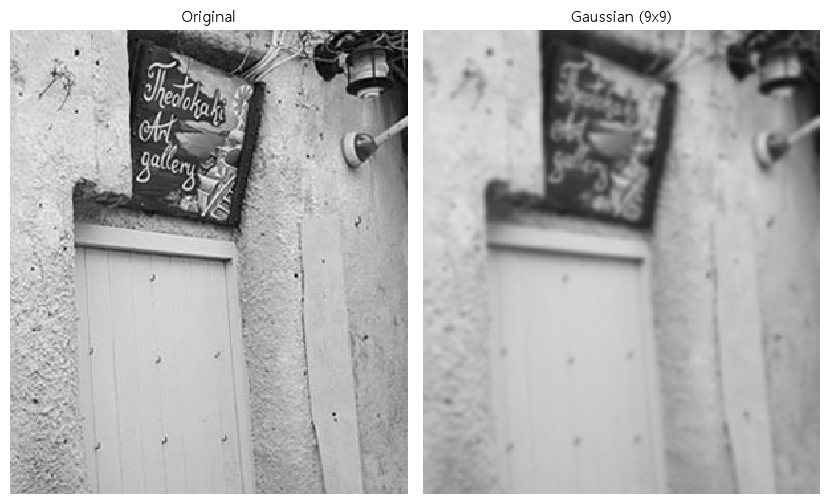

In [3]:
image = cv2.imread("../multi_info/images/dog.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("영상 파일 읽기 오류")

cv2.imshow("Original", image)

gaus = cv2.GaussianBlur(image, (9,9), 0)
cv2.imshow("Gaussian (9x9)", gaus)

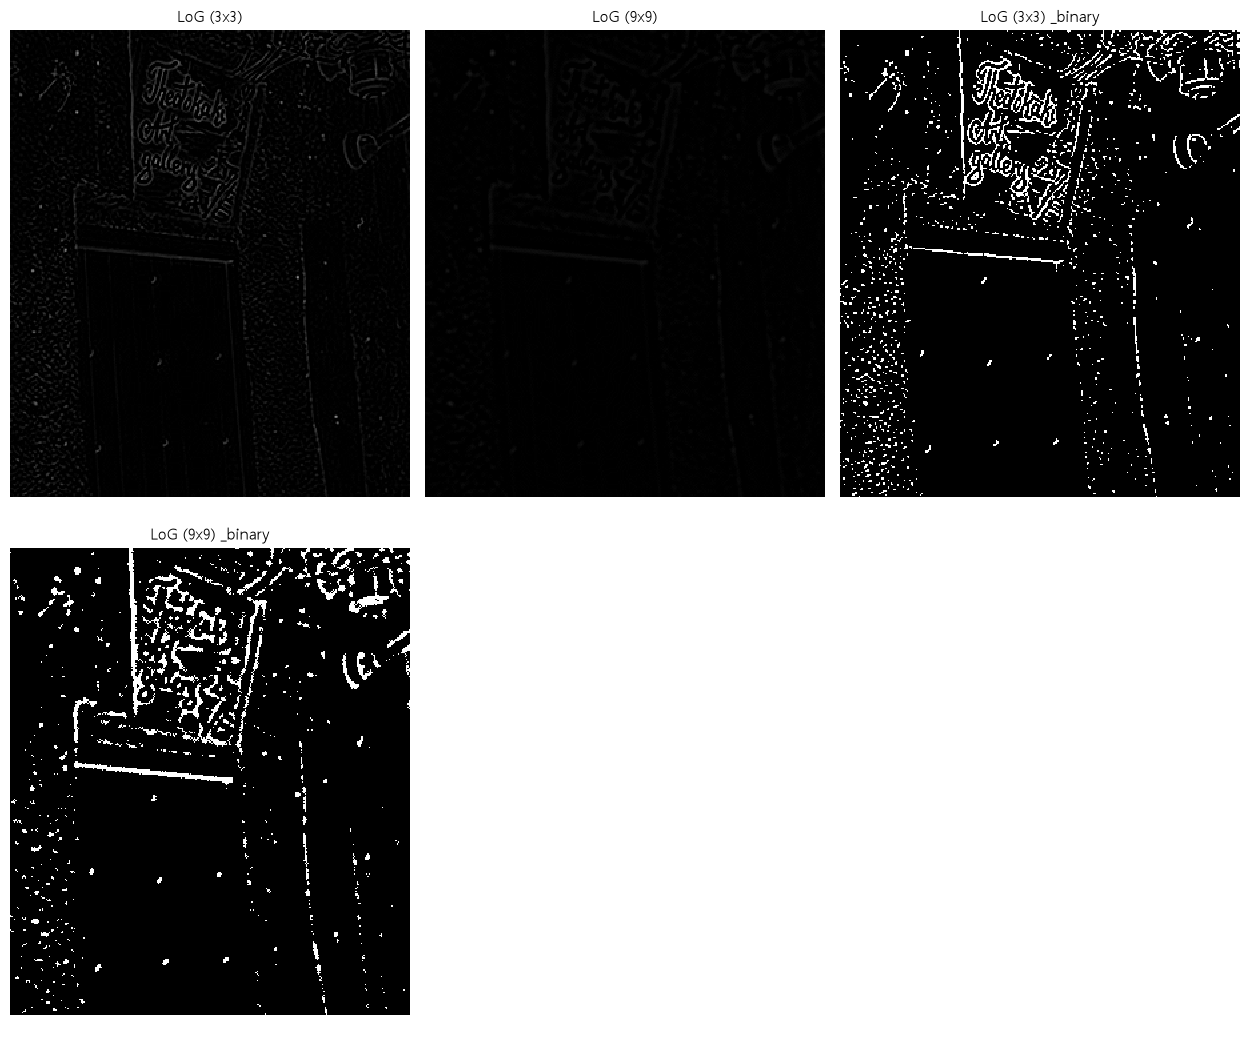

In [5]:
gaus1 = cv2.GaussianBlur(image, (3,3), 0)
gaus2 = cv2.GaussianBlur(image, (9,9), 0)

log1 = cv2.Laplacian(gaus1, cv2.CV_16S, 3)
log2 = cv2.Laplacian(gaus2, cv2.CV_16S, 9)
cv2.imshow("LoG (3x3)", log1)
cv2.imshow("LoG (9x9)", log2)

_, log1 = cv2.threshold(log1, 20, 255, cv2.THRESH_BINARY)
_, log2 = cv2.threshold(log2, 5, 255, cv2.THRESH_BINARY)
cv2.imshow("LoG (3x3) _binary", log1)
cv2.imshow("LoG (9x9) _binary", log2)

82


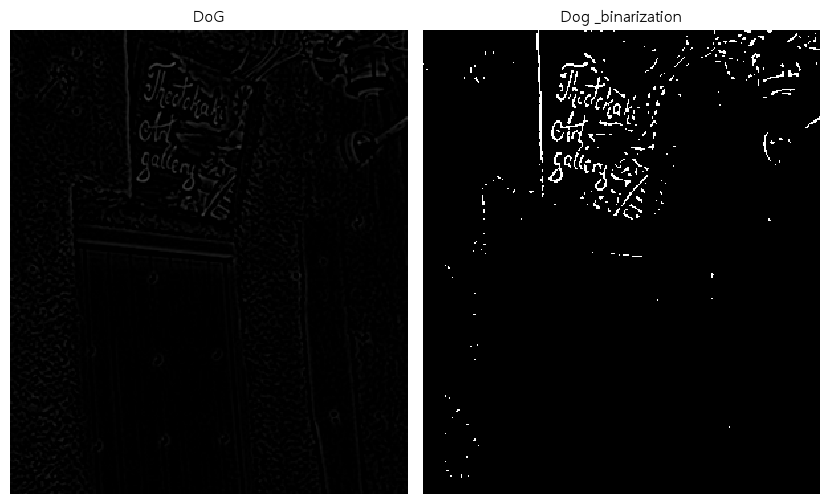

In [6]:
dog = cv2.subtract(gaus1, gaus2) # gaus1 - gaus2
print(np.max(dog))
cv2.imshow("DoG", dog)
_, dog2 = cv2.threshold(dog, 20, 255, cv2.THRESH_BINARY)
cv2.imshow("Dog _binarization", dog2)

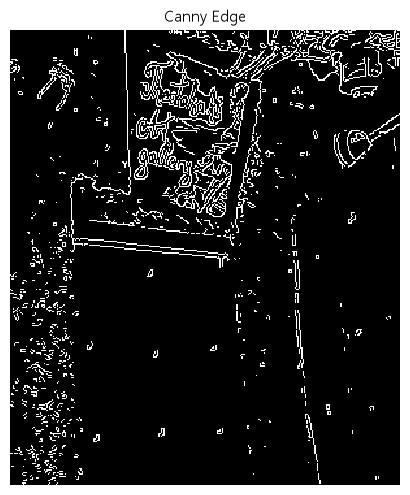

In [7]:
## canny edge
canny = cv2.Canny(image, 210, 240)
cv2.imshow("Canny Edge", canny)

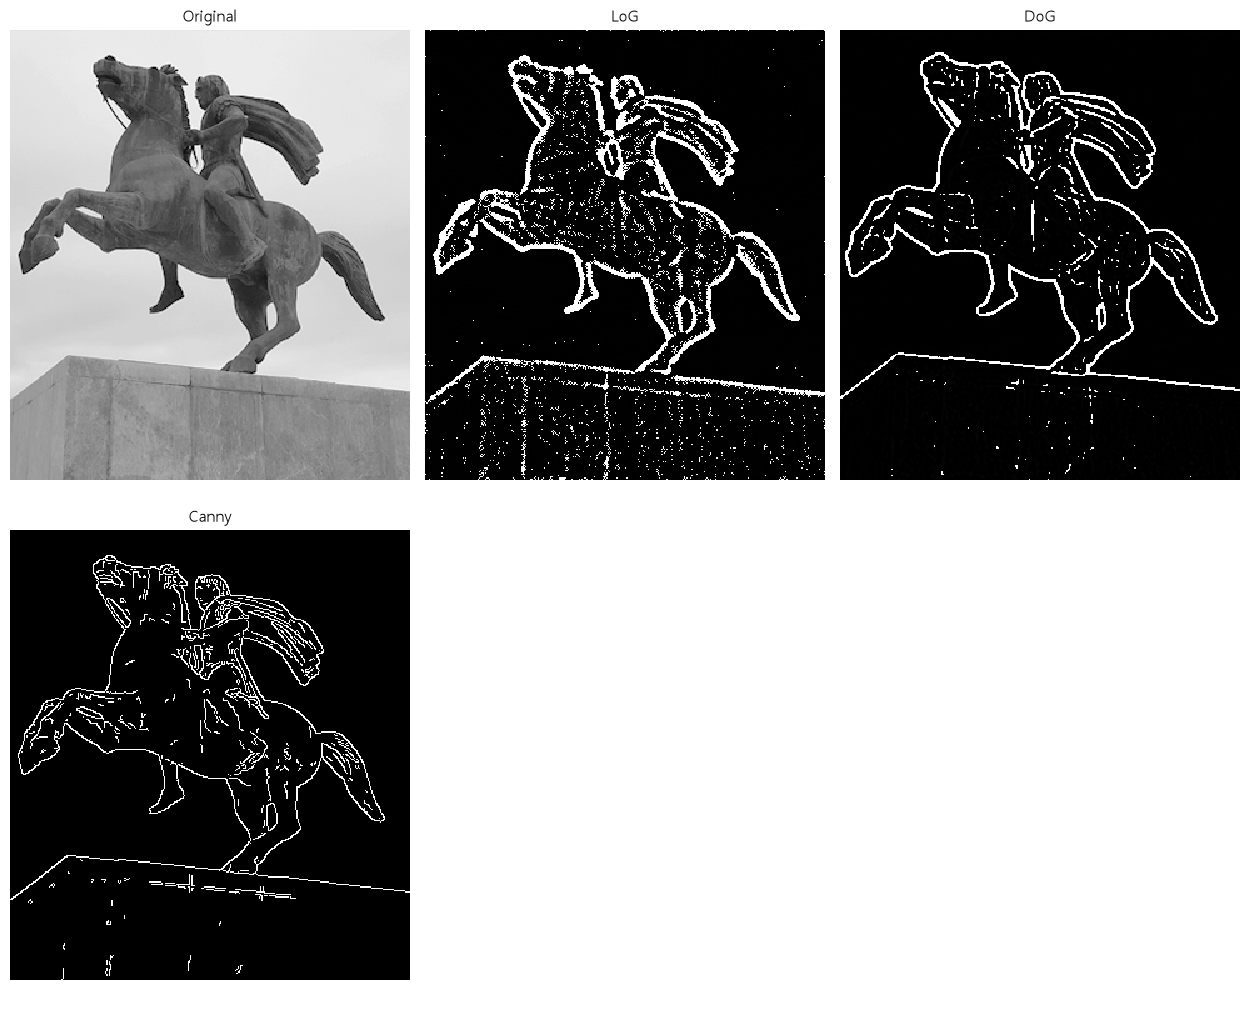

In [9]:
image2 = cv2.imread("../multi_info/images/canny.jpg", cv2.IMREAD_GRAYSCALE)
if image2 is None: raise Exception("영상 파일 읽기 오류")
gaus1 = cv2.GaussianBlur(image2, (3,3), 0)
gaus2 = cv2.GaussianBlur(image2, (9,9), 0)
laplace1 = cv2.Laplacian(gaus2, cv2.CV_16S, 9)
dog2 = cv2.subtract(gaus1, gaus2)
canny2 = cv2.Canny(image2, 100, 150)

l1 = laplace1>(np.max(laplace1)*0.1)
laplace1[l1] = 255
cv2.imshow("Original", image2)
cv2.imshow("LoG", laplace1)
d1 = dog2>(np.max(dog2)*0.1)
dog2[d1] = 255

cv2.imshow("DoG", dog2)
cv2.imshow("Canny", canny2)

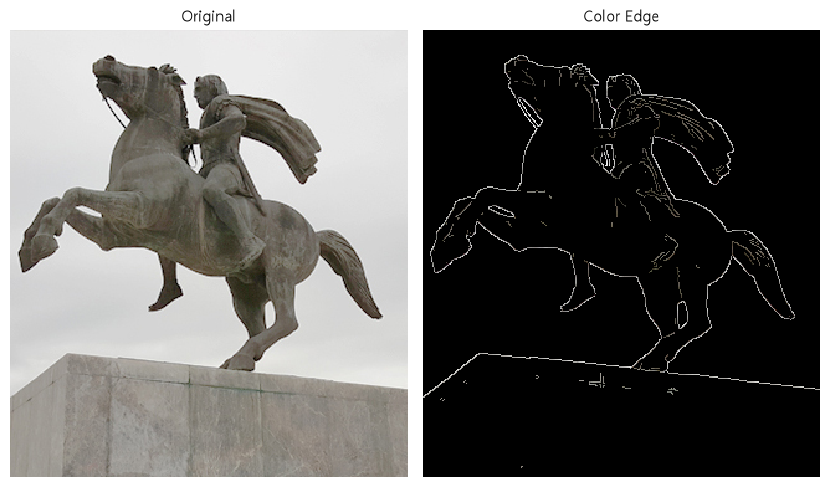

In [14]:
#color_edge = cv2.copyTo(image, mask=canny)
color_edge = cv2.bitwise_and(image, image, mask=canny)
cv2.imshow("Original", image)
cv2.imshow("Color Edge", color_edge)

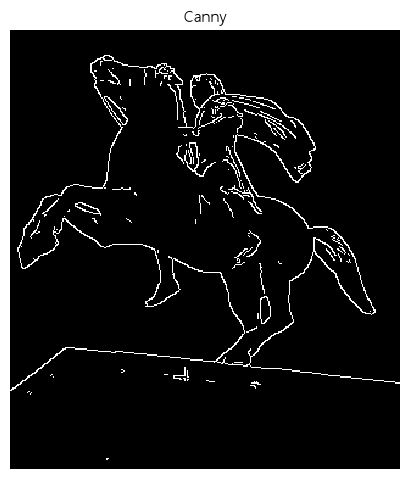

In [15]:
canny = cv2.Canny(gray_image, 150, 200)
cv2.imshow("Canny", canny)

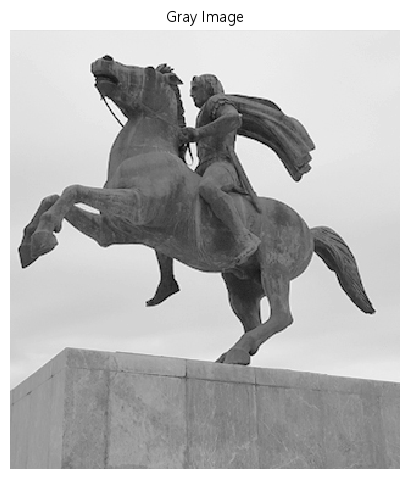

In [16]:
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2.imshow("Gray Image", gray_image)